In [2]:
import tensorflow as tf
from tensorflow.keras.models import Sequential 
from tensorflow.keras.layers import Flatten,Dense 
import matplotlib.pyplot as plt

In [3]:
mnist = tf.keras.datasets.mnist

In [4]:
(x_train,y_train) , (x_test,y_test) = mnist.load_data()

In [5]:
x_train = x_train/255.0 
x_test = x_test/255.0

In [6]:
model = Sequential([    
    Flatten(input_shape=(28,28)),   
    Dense(256,activation='relu'),    
    Dense(128,activation='relu'),    
    Dense(10,activation='softmax') 
])

/home/lenovo/.pyenv/versions/3.10.13/lib/python3.10/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
E0000 00:00:1794849511.987982    5581 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [7]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(   
    optimizer='sgd',    
    loss='sparse_categorical_crossentropy',   
    metrics=['accuracy'] 
)

In [9]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    validation_data=(x_test,y_test)
)

Epoch 1/5


W0000 00:00:1794849587.054096    5581 cpu_allocator_impl.cc:82] Allocation of 188160000 exceeds 10% of free system memory.


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8480 - loss: 0.5887 - val_accuracy: 0.9171 - val_loss: 0.3016
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9191 - loss: 0.2840 - val_accuracy: 0.9339 - val_loss: 0.2453
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9341 - loss: 0.2310 - val_accuracy: 0.9420 - val_loss: 0.2054
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9442 - loss: 0.1963 - val_accuracy: 0.9456 - val_loss: 0.1850
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9515 - loss: 0.1703 - val_accuracy: 0.9546 - val_loss: 0.1563


In [10]:
loss,accuracy = model.evaluate(x_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9546 - loss: 0.1563


In [11]:
print('loss :',loss) 
print('accuracy :',accuracy) 

loss : 0.15629197657108307
accuracy : 0.9545999765396118


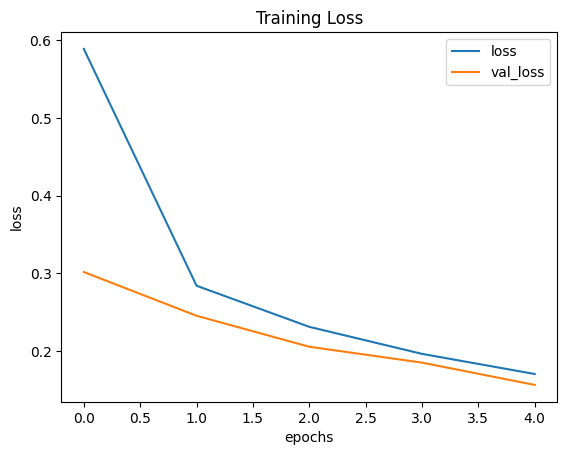

In [12]:
plt.plot(history.history['loss'],label='loss')
plt.plot(history.history['val_loss'],label='val_loss') 
plt.title("Training Loss")
plt.xlabel('epochs') 
plt.ylabel('loss') 
plt.legend() 
plt.show()

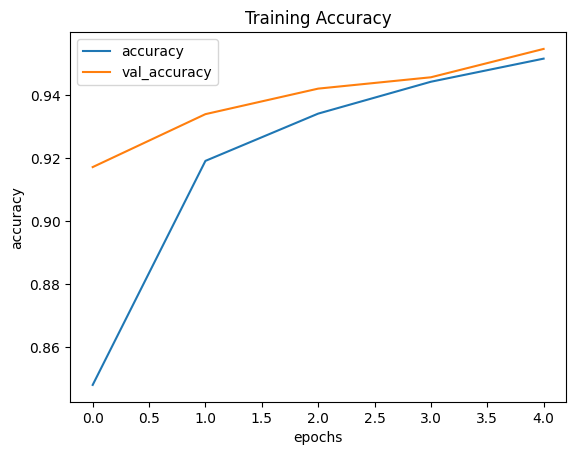

In [15]:
plt.plot(history.history['accuracy'],label='accuracy') 
plt.plot(history.history['val_accuracy'],label='val_accuracy') 
plt.title("Training Accuracy") 
plt.xlabel('epochs') 
plt.ylabel('accuracy')
plt.legend() 
plt.show()